In [7]:
# Cell 1

# Cell 1 — Class-E coefficients derived from ideal analytical waveform

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# --------------------------------------------------
# Specifications
# --------------------------------------------------
V_DD, P_out, f0 = 4.85, 1.65, 14.0e6

w0 = 2*np.pi*f0
T = 1/f0
T_half = T/2

# --------------------------------------------------
# 1. Analytical ideal Class-E switching solution
# --------------------------------------------------

a = 2 / np.sqrt(np.pi**2 + 4)

phi = np.pi - np.arctan(2/np.pi)

# Analytical coefficients
K_R = 2*a**2
K_C = 2*a**2/np.pi

# --------------------------------------------------
# 2. Derive K_L from the fundamental Fourier component
# --------------------------------------------------

# Use normalized conditions:
# V_DD = 1, P_out = 1, omega = 1

R_norm = K_R
I_R_norm = np.sqrt(2/R_norm)
I_DC_norm = a*I_R_norm
C_norm = K_C/R_norm

# Ideal drain-voltage waveform
theta = np.linspace(0, 2*np.pi, 200001)

v_D_norm = np.zeros_like(theta)

off = theta >= np.pi
th = theta[off]

v_D_norm[off] = (
    I_DC_norm*(th-np.pi)
    + I_R_norm*(
        np.cos(th+phi)-np.cos(np.pi+phi)
    )
) / C_norm

# Fundamental drain-voltage phasor
V1 = np.trapezoid(
    v_D_norm*np.exp(-1j*theta), theta
) / np.pi

# Fundamental load-current phasor
I1 = I_R_norm*np.exp(1j*(phi-np.pi/2))

# Fundamental impedance
Z1 = V1/I1

# Normalized series inductance coefficient
K_L = Z1.imag/Z1.real

# --------------------------------------------------
# 3. Compare against classical Sokal coefficients
# --------------------------------------------------

K_R_ref = 0.5768
K_C_ref = 0.1836
K_L_ref = 1.1525

print("IDEAL CLASS-E COEFFICIENT DERIVATION")
print("------------------------------------")
print(f"a   = {a:.8f}")
print(f"phi = {np.degrees(phi):.6f} degrees")
print()
print(f"K_R derived = {K_R:.8f} | Sokal = {K_R_ref:.8f}")
print(f"K_C derived = {K_C:.8f} | Sokal = {K_C_ref:.8f}")
print(f"K_L derived = {K_L:.8f} | Sokal = {K_L_ref:.8f}")
print()
print(f"Fundamental impedance: {Z1.real:.8f} + j{Z1.imag:.8f}")
print(f"Re(Z1)/R = {Z1.real/R_norm:.8f}")
print(f"Im(Z1)/R = {Z1.imag/R_norm:.8f}")

# --------------------------------------------------
# 4. Calculate physical circuit values
# --------------------------------------------------

R_opt = K_R * V_DD**2 / P_out
C_sh = K_C / (w0 * R_opt)
L_ser = K_L * R_opt / w0

I_DC_sk = P_out / V_DD
I_R = np.sqrt(2*P_out/R_opt)
phi_sk = phi

# --------------------------------------------------
# 5. Additional finite-Q tank components
# --------------------------------------------------

Q_L = 3.0

L_1 = L_ser
L_2 = Q_L * R_opt / w0
C_2 = 1 / (w0**2 * L_2)
L_total = L_1 + L_2

# --------------------------------------------------
# 6. Report
# --------------------------------------------------

print("\nPHYSICAL COMPONENT VALUES")
print("-------------------------")
print(f"R_opt     = {R_opt:.3f} Ω")
print(f"C_sh      = {C_sh*1e12:.2f} pF")
print(f"L_1       = {L_1*1e9:.2f} nH")
print(f"L_2       = {L_2*1e9:.2f} nH")
print(f"C_2       = {C_2*1e12:.2f} pF")
print(f"L_total   = {L_total*1e9:.2f} nH")

print(f"\nSokal I_DC = {I_DC_sk*1e3:.2f} mA")
print(f"Sokal I_R  = {I_R*1e3:.2f} mA")
print(f"Sokal phi  = {np.degrees(phi_sk):.2f} degrees")

print(f"R_opt = {R_opt:.3f} Ω,  C_sh = {C_sh*1e12:.2f} pF")
print(f"L_1 = {L_1*1e9:.2f} nH   (Sokal L_ser)")
print(f"L_2 = {L_2*1e9:.2f} nH   (tank L, Q_L = {Q_L})")
print(f"C_2 = {C_2*1e12:.2f} pF  (tank C, resonates with L_2 at f0)")
print(f"L_total = L_1 + L_2 = {L_total*1e9:.2f} nH")
print(f"Tank resonance check: L_2 · C_2 · ω0² = {L_2*C_2*w0**2:.6f}  (should be 1.000)")
print(f"Sokal: I_DC = {I_DC_sk*1e3:.2f} mA, I_R = {I_R*1e3:.2f} mA, φ = {np.degrees(phi_sk):.2f}°")

IDEAL CLASS-E COEFFICIENT DERIVATION
------------------------------------
a   = 0.53702927
phi = 147.518363 degrees

K_R derived = 0.57680088 | Sokal = 0.57680000
K_C derived = 0.18360142 | Sokal = 0.18360000
K_L derived = 1.15249413 | Sokal = 1.15250000

Fundamental impedance: 0.57680088 + j0.66475963
Re(Z1)/R = 1.00000000
Im(Z1)/R = 1.15249413

PHYSICAL COMPONENT VALUES
-------------------------
R_opt     = 8.223 Ω
C_sh      = 253.83 pF
L_1       = 107.73 nH
L_2       = 280.44 nH
C_2       = 460.83 pF
L_total   = 388.17 nH

Sokal I_DC = 340.21 mA
Sokal I_R  = 633.50 mA
Sokal phi  = 147.52 degrees
R_opt = 8.223 Ω,  C_sh = 253.83 pF
L_1 = 107.73 nH   (Sokal L_ser)
L_2 = 280.44 nH   (tank L, Q_L = 3.0)
C_2 = 460.83 pF  (tank C, resonates with L_2 at f0)
L_total = L_1 + L_2 = 388.17 nH
Tank resonance check: L_2 · C_2 · ω0² = 1.000000  (should be 1.000)
Sokal: I_DC = 340.21 mA, I_R = 633.50 mA, φ = 147.52°


In [2]:
# Cell 2

def sokal_waveforms(theta):
    theta = np.asarray(theta)
    v_D = np.zeros_like(theta, dtype=float)
    i_sw = np.zeros_like(theta, dtype=float)
    i_L = I_R * np.sin(theta + phi_sk)
    on  = (theta % (2*np.pi)) < np.pi
    off = ~on
    i_sw[on] = I_DC_sk - i_L[on]
    th = theta[off]
    th_local = th % (2*np.pi)
    dt = (th_local - np.pi) / w0
    v_D[off] = (1.0/C_sh) * (
        I_DC_sk * dt + (I_R/w0)*(np.cos(th_local+phi_sk) - np.cos(np.pi+phi_sk))
    )
    return dict(v_D=v_D, i_sw=i_sw, i_L=i_L)

theta = np.linspace(0, 2*np.pi, 1000, endpoint=False)
sokal = sokal_waveforms(theta)

In [3]:
# Cell 3

def make_f_on(I_DC, R_on):
    def f(t, y):
        i_L, v_C2 = y
        v_D = R_on * (I_DC - i_L)
        return [(v_D - v_C2 - R_opt*i_L) / L_total, i_L / C_2]
    return f

def make_f_off(I_DC):
    def f(t, y):
        v_D, i_L, v_C2 = y
        return [(I_DC - i_L) / C_sh, (v_D - v_C2 - R_opt*i_L) / L_total, i_L / C_2]
    return f

def honest_cycle(I_DC, R_on=0.0, n_warmup=500, n_samples=500):
    f_on  = make_f_on(I_DC, R_on)
    f_off = make_f_off(I_DC)
    i_L, v_C2 = 0.0, 0.0
    sol_on = sol_off = None
    for _ in range(n_warmup):
        sol_on = solve_ivp(f_on, [0, T_half], [i_L, v_C2],
                           method='LSODA', rtol=1e-10, atol=1e-13, dense_output=True)
        i_L, v_C2 = sol_on.y[0,-1], sol_on.y[1,-1]
        v_D_end_on = R_on * (I_DC - i_L)
        sol_off = solve_ivp(f_off, [0, T_half], [v_D_end_on, i_L, v_C2],
                            method='LSODA', rtol=1e-10, atol=1e-13, dense_output=True)
        i_L, v_C2 = sol_off.y[1,-1], sol_off.y[2,-1]

    t_on  = np.linspace(0, T_half, n_samples, endpoint=False)
    t_off = np.linspace(0, T_half, n_samples, endpoint=False)
    i_L_on  = sol_on.sol(t_on)[0]
    v_D_on  = R_on * (I_DC - i_L_on) if R_on > 0 else np.zeros_like(t_on)
    v_D_off = sol_off.sol(t_off)[0]
    i_L_off = sol_off.sol(t_off)[1]

    t_full    = np.concatenate([t_on, T_half + t_off])
    v_D_full  = np.concatenate([v_D_on, v_D_off])
    i_L_full  = np.concatenate([i_L_on, i_L_off])
    i_sw_full = np.concatenate([I_DC - i_L_on, np.zeros_like(i_L_off)])

    return dict(t=t_full, v_D=v_D_full, i_L=i_L_full, i_sw=i_sw_full,
                v_D_avg=np.trapezoid(v_D_full, t_full) / T,
                v_D_peak=v_D_full.max(),
                v_D_turnon=v_D_off[-1],
                i_L_turnon=i_L_off[-1])

def solve_steady_state(R_on=0.0):
    # Convergence sanity: compare 500 vs 1000 warmup
    for I_test in (0.7*I_DC_sk, I_DC_sk, 1.3*I_DC_sk):
        h1 = honest_cycle(I_test, R_on, n_warmup=500)
        h2 = honest_cycle(I_test, R_on, n_warmup=1000)
        delta = abs(h2['v_D_avg'] - h1['v_D_avg'])
        if delta > 1e-3:
            print(f"  WARN: I={I_test*1e3:.0f} mA, <v_D> moves {delta*1e3:.2f} mV between 500 and 1000 warmups")

    def resid(I):
        return honest_cycle(I, R_on, n_warmup=500)['v_D_avg'] - V_DD
    I_sol = brentq(resid, 0.7*I_DC_sk, 1.3*I_DC_sk, xtol=1e-7)
    h = honest_cycle(I_sol, R_on, n_warmup=1000)
    return h, I_sol, h['v_D_avg'] - V_DD

honest, I_DC_h, resid_h = solve_steady_state(0.0)
print(f"I_DC solution   = {I_DC_h*1e3:.3f} mA  (Sokal: {I_DC_sk*1e3:.3f} mA)")
print(f"Residual <v_D>  = {resid_h*1e3:+.4f} mV  (target < 10 mV)")

I_DC solution   = 377.587 mA  (Sokal: 340.206 mA)
Residual <v_D>  = +0.0000 mV  (target < 10 mV)



metric                 |   Sokal (Q_L=∞) |   Honest Q_L=3 |      delta
----------------------------------------------------------------------
v_D peak (V)           |          17.276 |         19.357 |     +12.0%
v_D @ turn-on (V)      |          0.0000 |         0.5129 |   +0.5129
i_L peak (mA)          |           633.5 |          750.1 |    +116.6
i_L @ turn-on (mA)     |           340.2 |          219.9 |    -120.3

Energy balance at R_on=0, Q_L=3.0:
  P_in                 =  1831.30 mW
  P_load               =  1830.56 mW
  P_ZVS                =     0.47 mW
  residual (P_in - P_load - P_ZVS) =   +0.269 mW


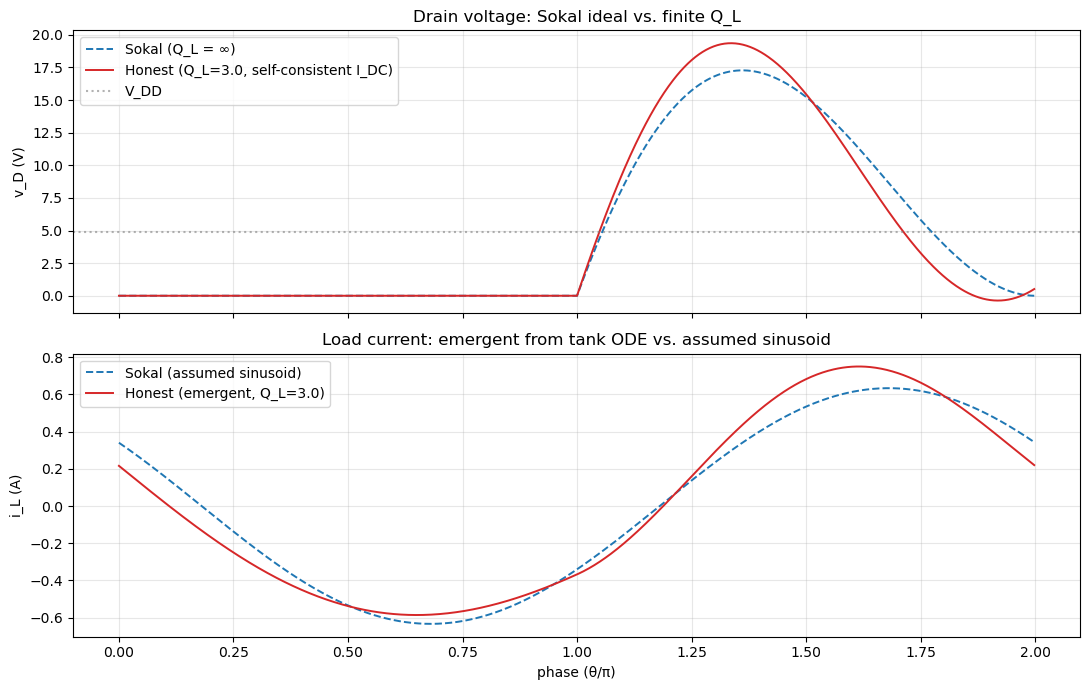

In [4]:
# Cell 4

print(f"\n{'metric':<22} | {'Sokal (Q_L=∞)':>15} | {'Honest Q_L=3':>14} | {'delta':>10}")
print("-" * 70)
print(f"{'v_D peak (V)':<22} | {sokal['v_D'].max():>15.3f} | {honest['v_D_peak']:>14.3f} | "
      f"{100*(honest['v_D_peak']/sokal['v_D'].max()-1):>+9.1f}%")
print(f"{'v_D @ turn-on (V)':<22} | {sokal['v_D'][0]:>15.4f} | {honest['v_D_turnon']:>14.4f} | "
      f"{honest['v_D_turnon']-sokal['v_D'][0]:>+9.4f}")
print(f"{'i_L peak (mA)':<22} | {I_R*1e3:>15.1f} | {honest['i_L'].max()*1e3:>14.1f} | "
      f"{(honest['i_L'].max()-I_R)*1e3:>+9.1f}")
print(f"{'i_L @ turn-on (mA)':<22} | {I_R*np.sin(phi_sk)*1e3:>15.1f} | "
      f"{honest['i_L_turnon']*1e3:>14.1f} | "
      f"{(honest['i_L_turnon']-I_R*np.sin(phi_sk))*1e3:>+9.1f}")

P_load_0 = np.trapezoid((honest['i_L']**2) * R_opt, honest['t']) / T
P_ZVS_0  = 0.5 * C_sh * honest['v_D_turnon']**2 * f0
P_in_0   = V_DD * I_DC_h
print(f"\nEnergy balance at R_on=0, Q_L={Q_L}:")
print(f"  P_in                 = {P_in_0*1e3:8.2f} mW")
print(f"  P_load               = {P_load_0*1e3:8.2f} mW")
print(f"  P_ZVS                = {P_ZVS_0*1e3:8.2f} mW")
print(f"  residual (P_in - P_load - P_ZVS) = {(P_in_0 - P_load_0 - P_ZVS_0)*1e3:+8.3f} mW")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(theta/np.pi, sokal['v_D'], 'C0--', lw=1.4, label='Sokal (Q_L = ∞)')
ax[0].plot(honest['t']/T_half, honest['v_D'], 'C3-', lw=1.4, label=f'Honest (Q_L={Q_L}, self-consistent I_DC)')
ax[0].axhline(V_DD, color='gray', ls=':', alpha=0.6, label='V_DD')
ax[0].set_ylabel('v_D (V)'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title('Drain voltage: Sokal ideal vs. finite Q_L')

ax[1].plot(theta/np.pi, sokal['i_L'], 'C0--', lw=1.4, label='Sokal (assumed sinusoid)')
ax[1].plot(honest['t']/T_half, honest['i_L'], 'C3-', lw=1.4, label=f'Honest (emergent, Q_L={Q_L})')
ax[1].set_xlabel('phase (θ/π)'); ax[1].set_ylabel('i_L (A)')
ax[1].legend(); ax[1].grid(alpha=0.3)
ax[1].set_title('Load current: emergent from tank ODE vs. assumed sinusoid')
plt.tight_layout(); plt.show()


 R_on |    I_DC |  v_Dpk |  v_D@on |  P_load |  P_Ron |  P_ZVS |    P_in |  balance |   eff |    resid
---------------------------------------------------------------------------------------------------------
 0.00 |   377.6 |  19.36 |  +0.513 |  1830.6 |    0.0 |    0.5 |  1831.3 |    +0.27 | 100.0% |   +0.00
 0.10 |   371.9 |  19.12 |  +0.603 |  1773.2 |   29.8 |    0.6 |  1803.9 |    +0.26 | 98.3% |   -0.00
 0.20 |   366.5 |  18.89 |  +0.691 |  1718.5 |   57.8 |    0.8 |  1777.4 |    +0.23 | 96.7% |   +0.00
 0.40 |   356.0 |  18.45 |  +0.859 |  1616.2 |  109.0 |    1.3 |  1726.6 |    +0.12 | 93.6% |   +0.00
 0.60 |   346.1 |  18.04 |  +1.016 |  1522.5 |  154.3 |    1.8 |  1678.6 |    -0.04 | 90.7% |   +0.00
 0.80 |   336.8 |  17.65 |  +1.164 |  1436.6 |  194.5 |    2.4 |  1633.2 |    -0.24 | 88.0% |   -0.00
 1.00 |   327.9 |  17.28 |  +1.304 |  1357.5 |  230.2 |    3.0 |  1590.3 |    -0.48 | 85.4% |   +0.00


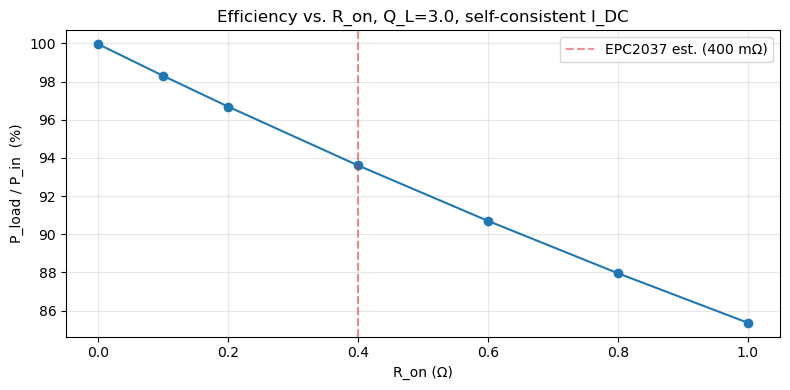

In [5]:
# Cell 5

print(f"\n{'R_on':>5} | {'I_DC':>7} | {'v_Dpk':>6} | {'v_D@on':>7} | "
      f"{'P_load':>7} | {'P_Ron':>6} | {'P_ZVS':>6} | {'P_in':>7} | "
      f"{'balance':>8} | {'eff':>5} | {'resid':>8}")
print("-" * 105)
results = []
for R_on in [0.0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
    h, I_dc, resid = solve_steady_state(R_on)
    P_load = np.trapezoid((h['i_L']**2) * R_opt, h['t']) / T
    P_Ron  = R_on * np.trapezoid(h['i_sw']**2, h['t']) / T
    P_ZVS  = 0.5 * C_sh * h['v_D_turnon']**2 * f0
    P_in   = V_DD * I_dc
    balance = P_in - P_load - P_Ron - P_ZVS
    eff = P_load / P_in if P_in > 0 else 0
    print(f"{R_on:>5.2f} | {I_dc*1e3:>7.1f} | {h['v_D_peak']:>6.2f} | "
          f"{h['v_D_turnon']:>+7.3f} | {P_load*1e3:>7.1f} | "
          f"{P_Ron*1e3:>6.1f} | {P_ZVS*1e3:>6.1f} | {P_in*1e3:>7.1f} | "
          f"{balance*1e3:>+8.2f} | {100*eff:>4.1f}% | {resid*1e3:>+7.2f}")
    results.append((R_on, eff))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r[0] for r in results], [100*r[1] for r in results], 'o-')
ax.axvline(0.4, color='C3', ls='--', alpha=0.5, label='EPC2037 est. (400 mΩ)')
ax.set_xlabel('R_on (Ω)')
ax.set_ylabel('P_load / P_in  (%)')
ax.set_title(f'Efficiency vs. R_on, Q_L={Q_L}, self-consistent I_DC')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()